# Particles regroup from spatial location instead of initial position

- Particles are released every 5 days, the grouping is not so obvious. We will now group according to the date when they cross certain threshold.

In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
from xhistogram.xarray import histogram as xhist


In [2]:
def calc_hist(ds):
    return xhist(
        ds.lon,
        ds.lat,
        bins=[lon_bins, lat_bins],
        dim=["trajectory", ],
        bin_dim_suffix=""
    )

## 1) We randomly select 100 particles from different release stores in one year

In [3]:
path0 = '/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_67891/'
path0

'/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_67891/'

In [4]:
# !ls '/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_67891/'

In [5]:
stores = np.random.choice(glob(path0+'*2008*.zarr'),size=10,replace=False)
stores

array(['/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_67891/Parcels_run_67891_2008-07-22 00:00:00.zarr',
       '/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_67891/Parcels_run_67891_2008-08-16 00:00:00.zarr',
       '/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_67891/Parcels_run_67891_2008-05-03 00:00:00.zarr',
       '/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_67891/Parcels_run_67891_2008-06-02 00:00:00.zarr',
       '/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_67891/Parcels_run_67891_2008-10-15 00:00:00.zarr',
       '/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_67891/Parcels_run_67891_2008-03-09 00:00:00.zarr',
       '/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_67891/Parcels_run_67891_2008-10-20 00:00:00.zarr',
       '/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_67891/Parcels_run_67891_2008-08-06 00:00:00.zarr',
       '/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v

In [6]:
ds_list = [xr.open_zarr(s) for s in stores]
ds = xr.concat(ds_list,dim='trajectory')

In [7]:
ds = ds.drop_vars(['z','sal','temp','ndry','nrefine'])
ds

<xarray.Dataset> Size: 2GB
Dimensions:     (trajectory: 101050, obs: 740)
Coordinates:
  * obs         (obs) int32 3kB 0 1 2 3 4 5 6 7 ... 733 734 735 736 737 738 739
  * trajectory  (trajectory) int64 808kB 0 2 3 5 8 ... 16394 16395 16397 16398
Data variables:
    lat         (trajectory, obs) float64 598MB dask.array<chunksize=(10105, 185), meta=np.ndarray>
    lon         (trajectory, obs) float64 598MB dask.array<chunksize=(10105, 185), meta=np.ndarray>
    time        (trajectory, obs) datetime64[ns] 598MB dask.array<chunksize=(10105, 185), meta=np.ndarray>
Attributes:
    Conventions:            CF-1.6/CF-1.7
    feature_type:           trajectory
    ncei_template_version:  NCEI_NetCDF_Trajectory_Template_v2.0
    parcels_kernels:        SampleParticleDeleteNorthSampleTSAdvectionRK4_3D_...
    parcels_mesh:           spherical
    parcels_version:        3.1.2

In [8]:
num_valid_obs_steps = int(ds.lat.notnull().any('trajectory').sum().compute().data[()])
ds = ds.isel(obs=slice(None, num_valid_obs_steps))
ds

<xarray.Dataset> Size: 2GB
Dimensions:     (trajectory: 101050, obs: 740)
Coordinates:
  * obs         (obs) int32 3kB 0 1 2 3 4 5 6 7 ... 733 734 735 736 737 738 739
  * trajectory  (trajectory) int64 808kB 0 2 3 5 8 ... 16394 16395 16397 16398
Data variables:
    lat         (trajectory, obs) float64 598MB dask.array<chunksize=(10105, 185), meta=np.ndarray>
    lon         (trajectory, obs) float64 598MB dask.array<chunksize=(10105, 185), meta=np.ndarray>
    time        (trajectory, obs) datetime64[ns] 598MB dask.array<chunksize=(10105, 185), meta=np.ndarray>
Attributes:
    Conventions:            CF-1.6/CF-1.7
    feature_type:           trajectory
    ncei_template_version:  NCEI_NetCDF_Trajectory_Template_v2.0
    parcels_kernels:        SampleParticleDeleteNorthSampleTSAdvectionRK4_3D_...
    parcels_mesh:           spherical
    parcels_version:        3.1.2

In [9]:
ds = ds.assign(start_time=ds.time.isel(obs=0).compute())
ds

<xarray.Dataset> Size: 2GB
Dimensions:     (trajectory: 101050, obs: 740)
Coordinates:
  * obs         (obs) int32 3kB 0 1 2 3 4 5 6 7 ... 733 734 735 736 737 738 739
  * trajectory  (trajectory) int64 808kB 0 2 3 5 8 ... 16394 16395 16397 16398
Data variables:
    lat         (trajectory, obs) float64 598MB dask.array<chunksize=(10105, 185), meta=np.ndarray>
    lon         (trajectory, obs) float64 598MB dask.array<chunksize=(10105, 185), meta=np.ndarray>
    time        (trajectory, obs) datetime64[ns] 598MB dask.array<chunksize=(10105, 185), meta=np.ndarray>
    start_time  (trajectory) datetime64[ns] 808kB 2008-07-22 ... 2008-04-13
Attributes:
    Conventions:            CF-1.6/CF-1.7
    feature_type:           trajectory
    ncei_template_version:  NCEI_NetCDF_Trajectory_Template_v2.0
    parcels_kernels:        SampleParticleDeleteNorthSampleTSAdvectionRK4_3D_...
    parcels_mesh:           spherical
    parcels_version:        3.1.2

## 2) Find when they crossed 2.5N,4N,5N,..12N
- Group according the date when they crossed the threshold
- start_time should be then time_treshold

In [10]:
ds = ds.compute()
ds

<xarray.Dataset> Size: 2GB
Dimensions:     (trajectory: 101050, obs: 740)
Coordinates:
  * obs         (obs) int32 3kB 0 1 2 3 4 5 6 7 ... 733 734 735 736 737 738 739
  * trajectory  (trajectory) int64 808kB 0 2 3 5 8 ... 16394 16395 16397 16398
Data variables:
    lat         (trajectory, obs) float64 598MB 0.8943 0.9296 ... 21.91 21.92
    lon         (trajectory, obs) float64 598MB -49.76 -49.75 ... -81.32 -81.35
    time        (trajectory, obs) datetime64[ns] 598MB 2008-07-22 ... 2008-10...
    start_time  (trajectory) datetime64[ns] 808kB 2008-07-22 ... 2008-04-13
Attributes:
    Conventions:            CF-1.6/CF-1.7
    feature_type:           trajectory
    ncei_template_version:  NCEI_NetCDF_Trajectory_Template_v2.0
    parcels_kernels:        SampleParticleDeleteNorthSampleTSAdvectionRK4_3D_...
    parcels_mesh:           spherical
    parcels_version:        3.1.2

In [11]:
thr_list = [2.5, 3.5, 5, 6, 7, 8, 9, 10, 11, 12]

In [12]:
def threshold_group(thr_list,ds):
    ds_m = ds
    hist_thr = {} 
    
    for i in range(len(thr_list)):
        cross = (ds.lat.shift(obs=1) < thr_list[i]) & (ds.lat >= thr_list[i])
        crossed = cross.any('obs') # false if it never reaches the threshold
        idx = cross.argmax('obs') # obs index of first crossing
        # ds = ds.assign(**{f'start_{thr_list[i]}N': ds.time.isel(obs=idx)})
        #particles that never cross threshold are NaN
        ds = ds.assign(**{f'start_{thr_list[i]}N': ds.time.isel(obs=idx).where(crossed)}) 
        #Particles that don't cross go to month 13
        ds_m = ds_m.assign(**{f'month_start_{thr_list[i]}N': ds[f'start_{thr_list[i]}N'].dt.month.fillna(13)})

        #histogram
        ds_m = ds_m.assign(thr_month=ds_m[f'month_start_{thr_list[i]}N'])

        hist_temporal = ds_m.groupby(["thr_month"]).apply(calc_hist)
        hist_temporal = hist_temporal.isel(obs=slice(1, None)).coarsen(obs=4 * 5, boundary="trim").sum()
        
        # store the hist
        hist_thr[f'hist_{thr_list[i]}N'] = hist_temporal

    
    return ds, ds_m, hist_thr

# ds_m = ds.assign(start_month=ds.start_time.dt.month)
# ds_m = ds_m.assign(thr_month=ds.time_treshold.dt.month)
# ds_m

In [13]:
lat_min=ds.lat.min().compute().data[()]
lon_min=ds.lon.min().compute().data[()]

lat_max=ds.lat.max().compute().data[()]
lon_max=ds.lon.max().compute().data[()]

lat_bins = np.linspace(lat_min, lat_max, 30)
lon_bins = np.linspace(lon_min, lon_max, 80)

In [14]:
nds,nds_m,hist_thr = threshold_group(thr_list,ds)
hist_thr

{'hist_2.5N': <xarray.DataArray 'histogram_lon_lat' (thr_month: 13, obs: 36, lon: 79, lat: 29)> Size: 9MB
 array([[[[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
 
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
 
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
 ...
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
 
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],


In [15]:
import cartopy.crs as ccrs
import cartopy.feature as cf
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import matplotlib.patches as mpatches

In [16]:
hist_thr[f'hist_{thr_list[0]}N']

<xarray.DataArray 'histogram_lon_lat' (thr_month: 13, obs: 36, lon: 79, lat: 29)> Size: 9MB
array([[[[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],

        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],

        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
...
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],

        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],

        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]]]], shape=(13, 36, 79, 29))
Coordinates:
  * obs        (obs) float64 288B 10.5 30.5 50.5 70.5 ... 670.5 690.5 710.5
  * lon        (lon) float64 632B -88.19 -87.3 -86.4 ... -20.23 -19.33 -18.44
  * lat        (lat) float64 232B -1.557 -0.4565 0.6441 ... 27.06 28.16 29.26
  * thr_month  (thr_month) float64 104B 1.0 2.0 3.0 4.0 ... 10.0 11.0 12.0 13.0

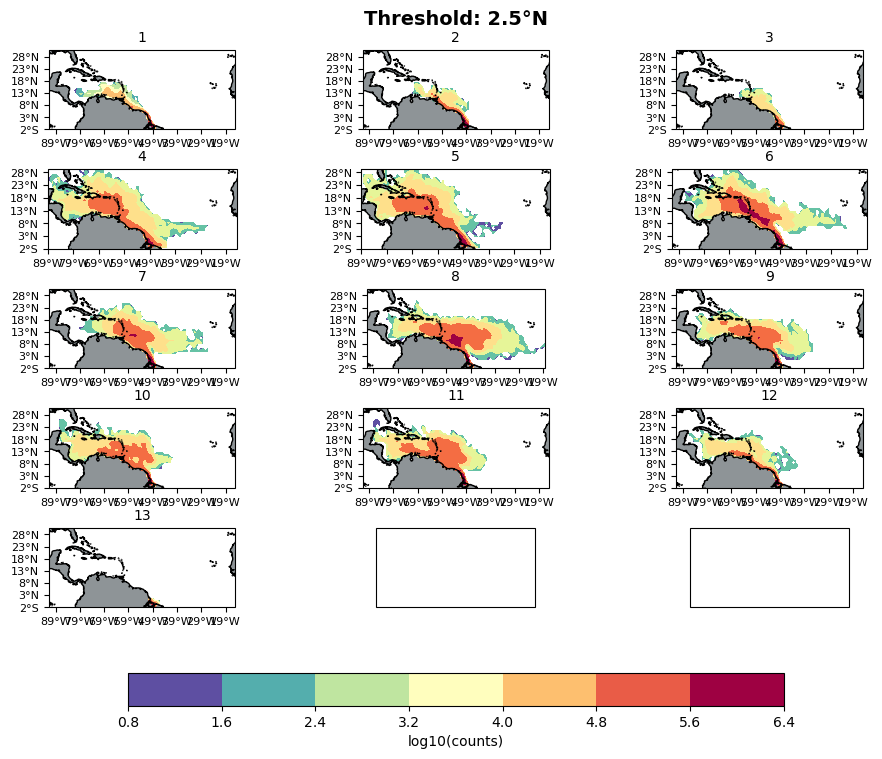

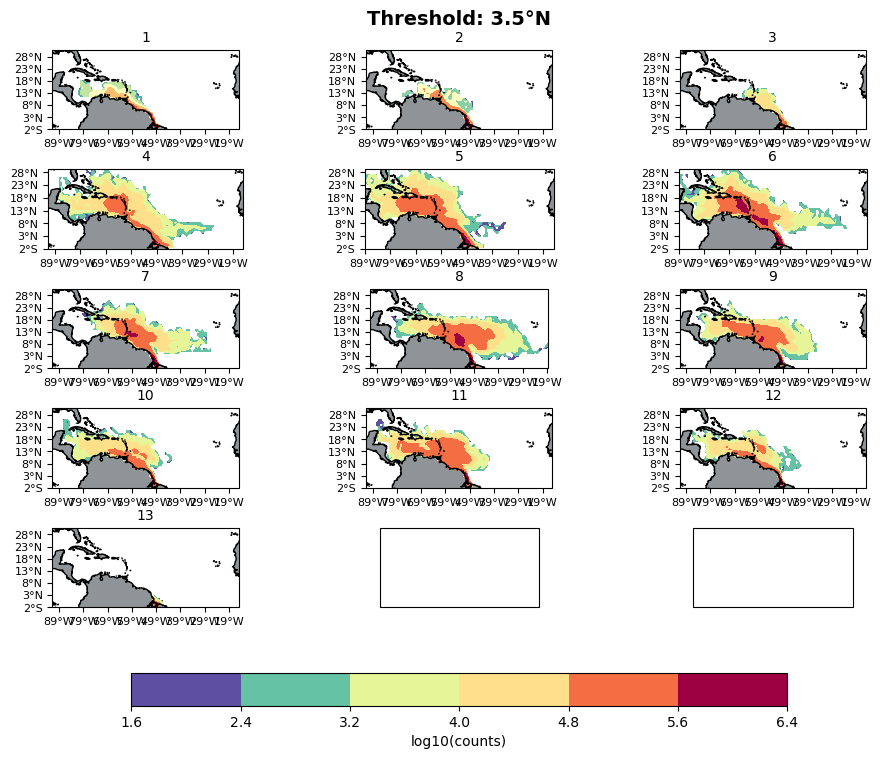

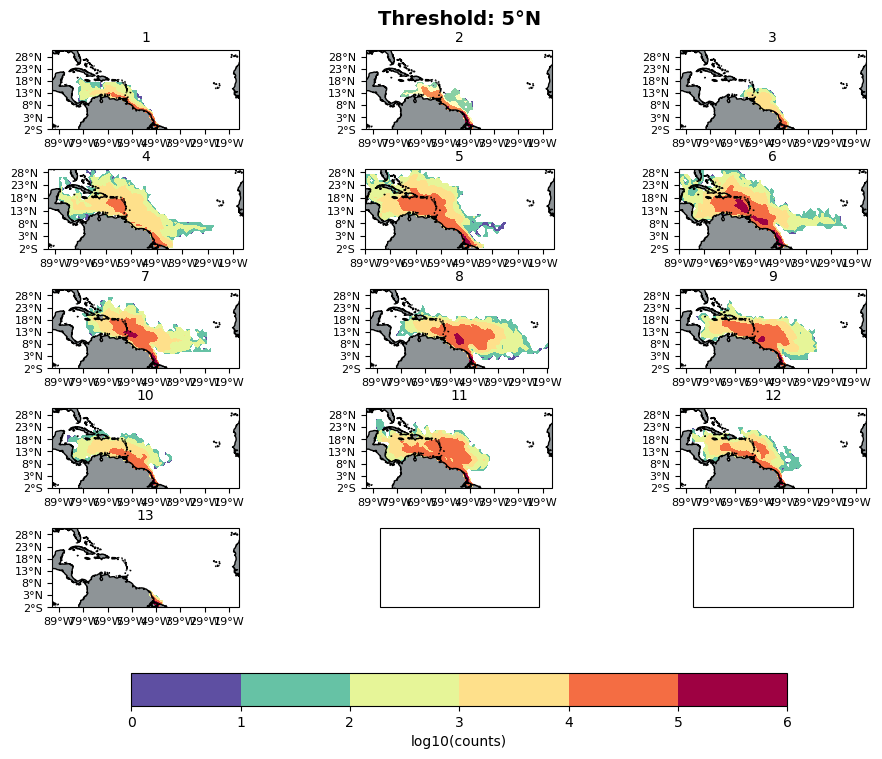

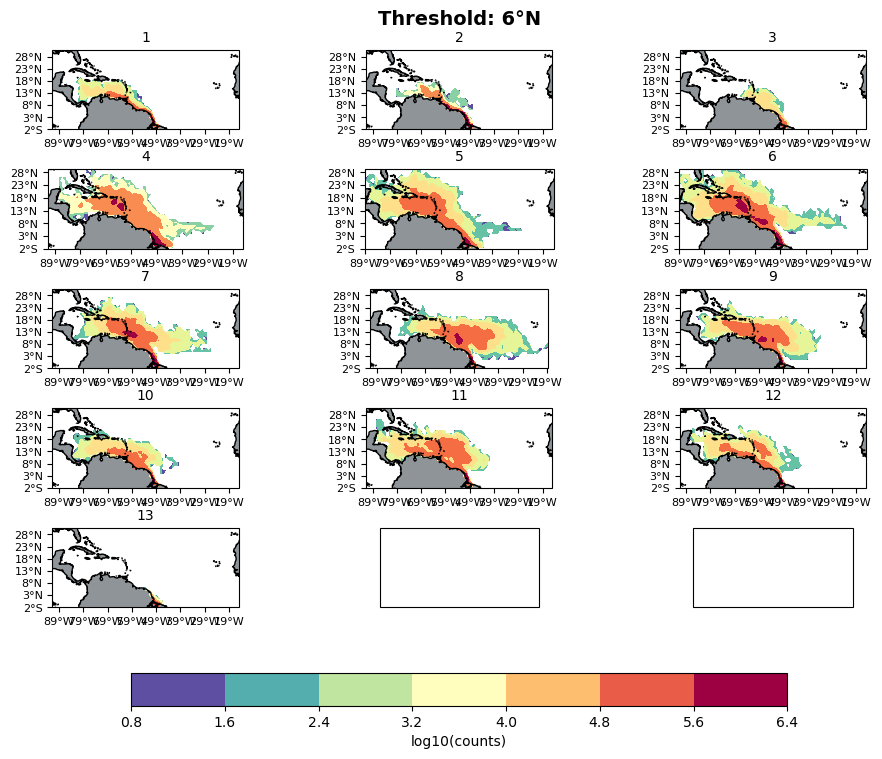

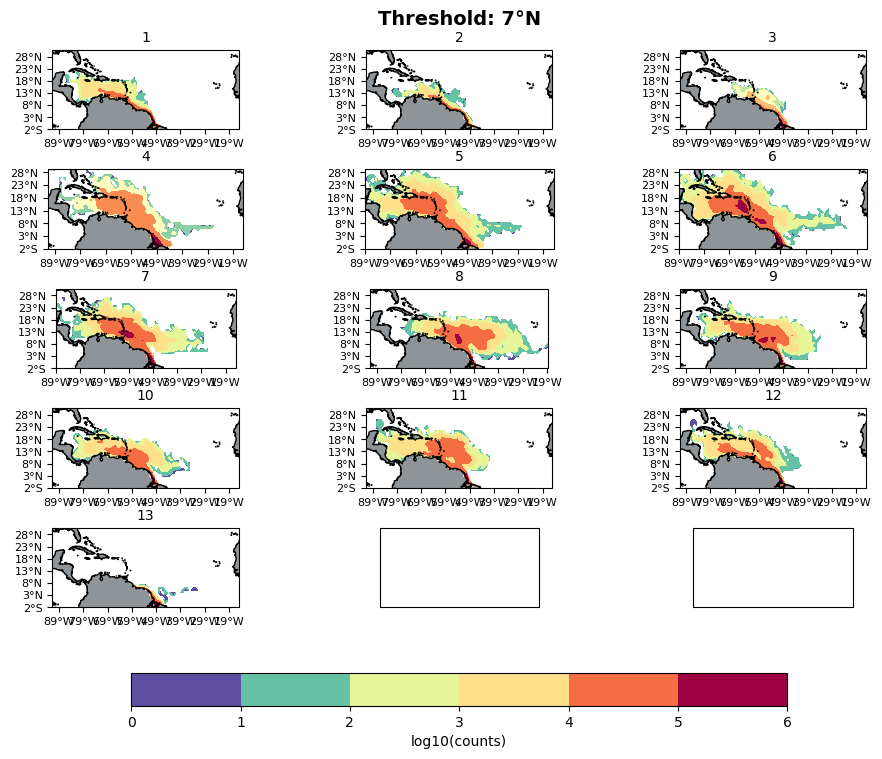

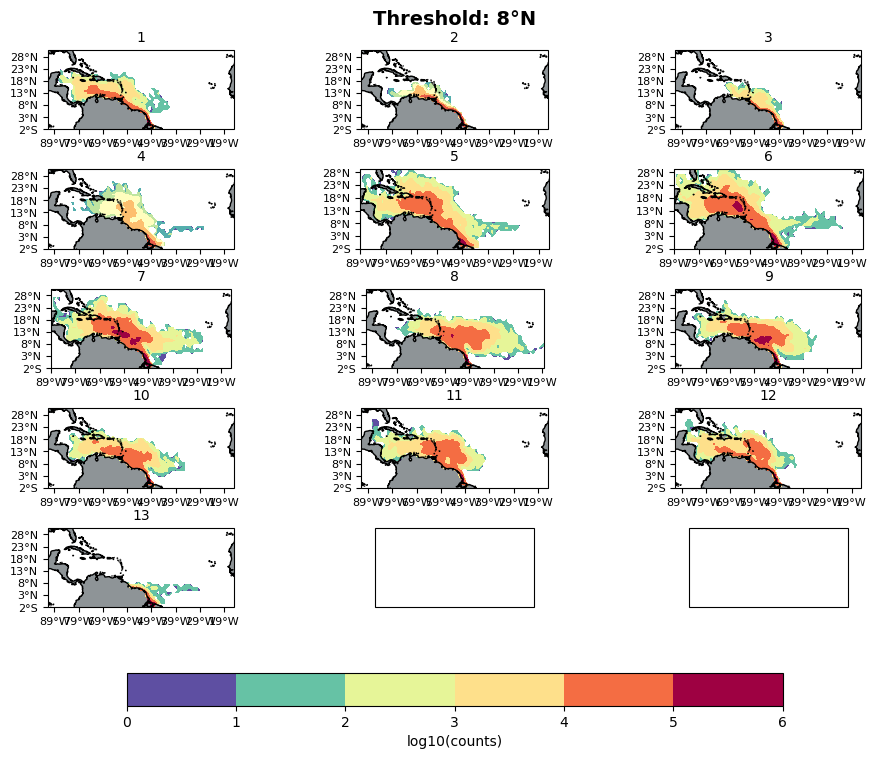

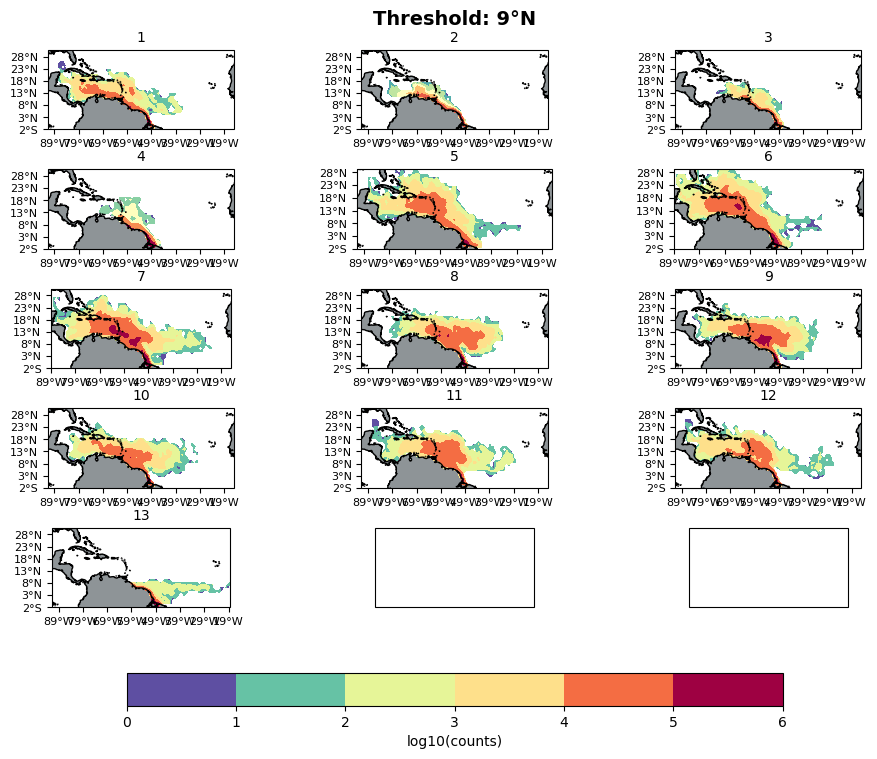

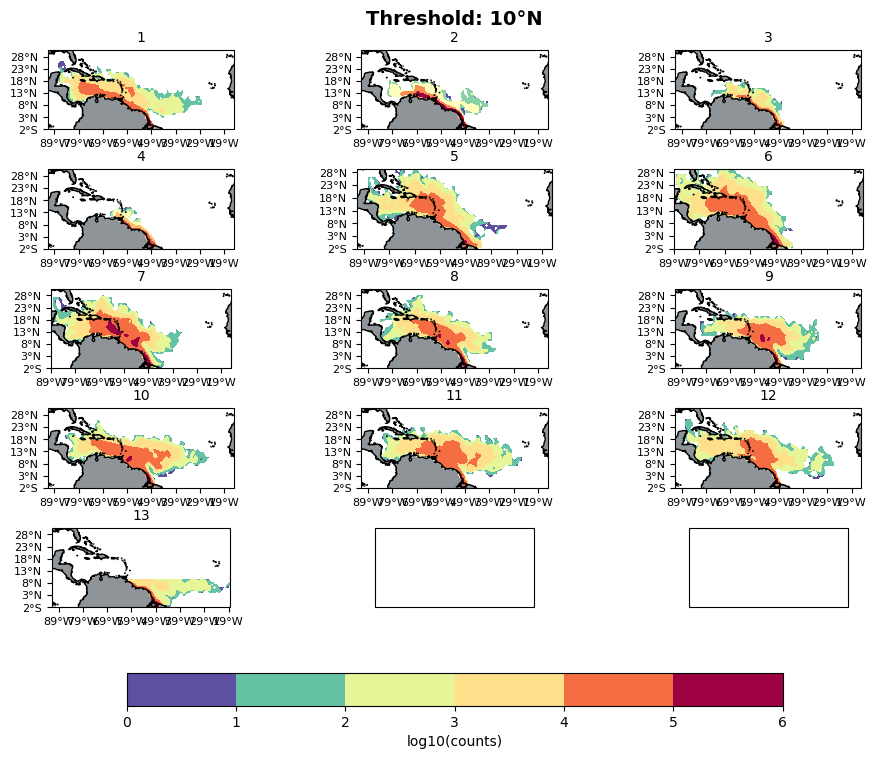

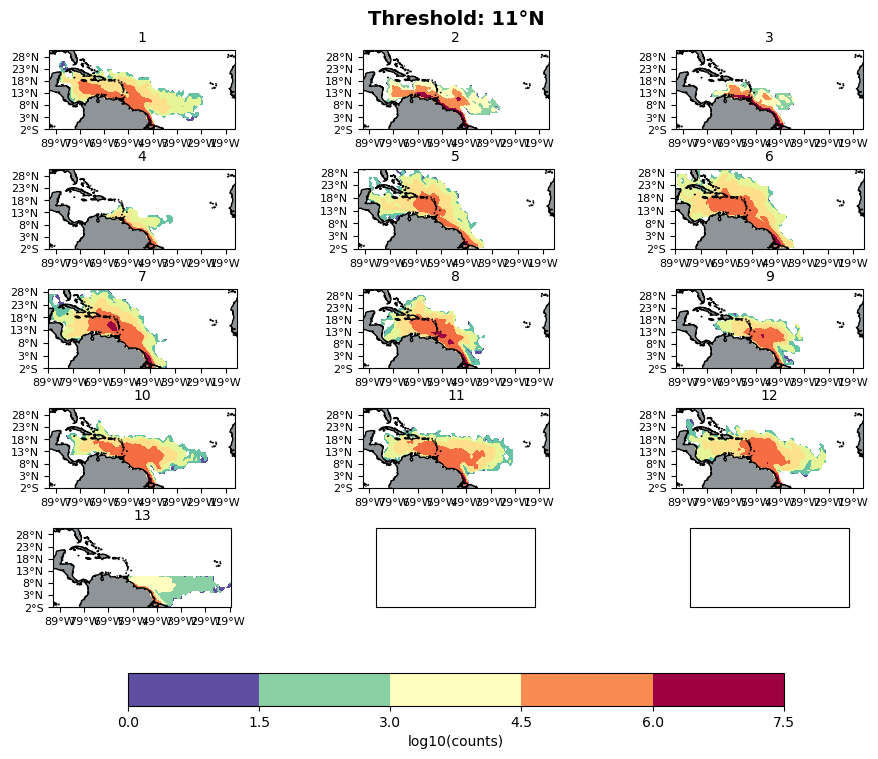

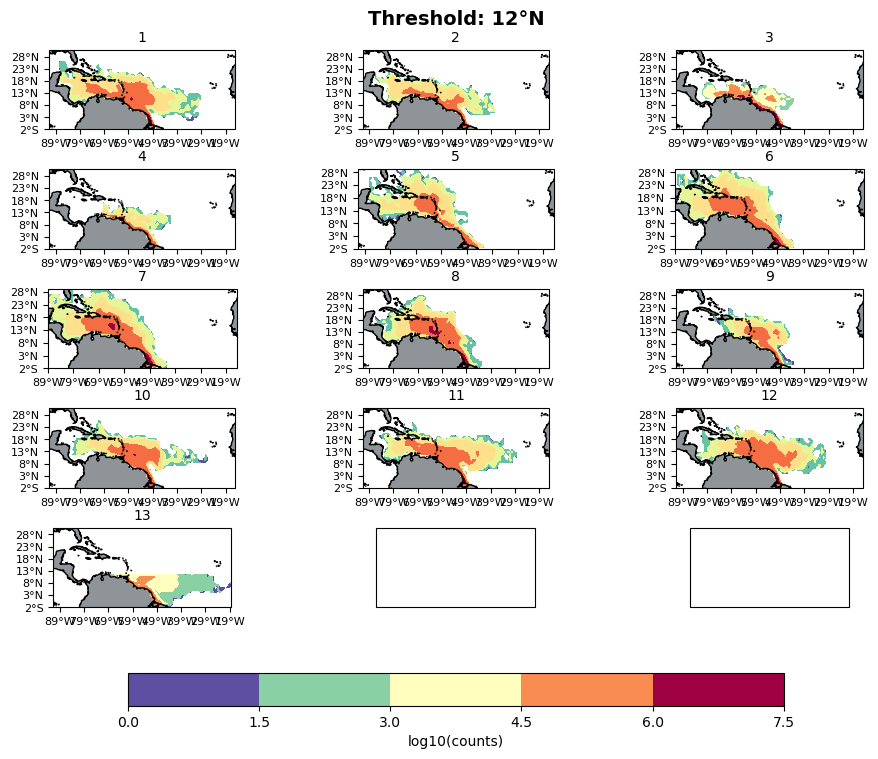

In [19]:
for ii in range(len(thr_list)):
    
    hist_ = hist_thr[f'hist_{thr_list[ii]}N']
    
    proj = ccrs.PlateCarree()
    
    fig, ax = plt.subplots(
        5, 3,
        figsize=(10, 8),                      # a bit wider, not so tall
        subplot_kw=dict(projection=proj)
    )
    ax = ax.ravel()
    
    for i in range(12+1):
        dd = hist_.sel(thr_month=i+1).sum("obs")
    
        # plot
        pcm = np.log10(dd).plot.contourf(
            x='lon', y='lat', ax=ax[i], transform=proj,
            add_colorbar=False, cmap='Spectral_r'
        )
    
        ax[i].coastlines()
        ax[i].add_feature(cf.LAND, facecolor='#8e9497ff', zorder=0)
        ax[i].set_title(i+1, fontsize=10)
    
        # ticks & labels
        ax[i].set_xticks(
            np.arange(np.floor(dd.lon.min()), np.ceil(dd.lon.max()) + 1e-6, 10),
            crs=proj
        )
        ax[i].set_yticks(
            np.arange(np.floor(dd.lat.min()), np.ceil(dd.lat.max()) + 1e-6, 5),
            crs=proj
        )
        ax[i].xaxis.set_major_formatter(
            LongitudeFormatter(number_format='.0f', degree_symbol='°')
        )
        ax[i].yaxis.set_major_formatter(
            LatitudeFormatter(number_format='.0f', degree_symbol='°')
        )
        ax[i].tick_params(labelsize=8)
        ax[i].set_xlabel('')
        ax[i].set_ylabel('')
    
    # Tighter spacing: reduce both wspace and hspace
    fig.subplots_adjust(
        left=0.05, right=0.95,
        bottom=0.08, top=0.90,
        wspace=0.15, hspace=0.50
    )
    
    # Optional: one shared colorbar at bottom
    cbar = fig.colorbar(
        pcm, ax=ax, orientation='horizontal',
        fraction=0.05, pad=0.10
    )
    cbar.ax.set_xlabel('log10(counts)', fontsize=10)
    
    fig.suptitle(f'Threshold: {thr_list[ii]}°N', fontsize=14, fontweight='bold', y=0.95)
    
    plt.show()

In [ ]:
for ii in range(len(thr_list)):
    
    hist_ = hist_thr[f'hist_{thr_list[ii]}N']
    
    proj = ccrs.PlateCarree()
    
    fig, ax = plt.subplots(
        4, 3,
        figsize=(10, 8),                      # a bit wider, not so tall
        subplot_kw=dict(projection=proj)
    )
    ax = ax.ravel()
    
    for i in range(12+1):
        dd = hist_.sel(thr_month=i+1).sum("obs")
    
        # plot
        pcm = np.log10(dd).plot(
            x='lon', y='lat', ax=ax[i], transform=proj,
            add_colorbar=False, cmap='Spectral_r'
        )
    
        ax[i].coastlines()
        ax[i].add_feature(cf.LAND, facecolor='#8e9497ff', zorder=0)
        ax[i].set_title(i+1, fontsize=10)
    
        # ticks & labels
        ax[i].set_xticks(
            np.arange(np.floor(dd.lon.min()), np.ceil(dd.lon.max()) + 1e-6, 10),
            crs=proj
        )
        ax[i].set_yticks(
            np.arange(np.floor(dd.lat.min()), np.ceil(dd.lat.max()) + 1e-6, 5),
            crs=proj
        )
        ax[i].xaxis.set_major_formatter(
            LongitudeFormatter(number_format='.0f', degree_symbol='°')
        )
        ax[i].yaxis.set_major_formatter(
            LatitudeFormatter(number_format='.0f', degree_symbol='°')
        )
        ax[i].tick_params(labelsize=8)
        ax[i].set_xlabel('')
        ax[i].set_ylabel('')
    
    # Tighter spacing: reduce both wspace and hspace
    fig.subplots_adjust(
        left=0.05, right=0.95,
        bottom=0.08, top=0.90,
        wspace=0.15, hspace=0.50
    )
    
    # Optional: one shared colorbar at bottom
    cbar = fig.colorbar(
        pcm, ax=ax, orientation='horizontal',
        fraction=0.05, pad=0.10
    )
    cbar.ax.set_xlabel('log10(counts)', fontsize=10)
    
    fig.suptitle(f'Threshold: {thr_list[ii]}°N', fontsize=14, fontweight='bold', y=0.95)
    
    plt.show()